# Acurácia de teste × tamanho da n-tupla — treino por épocas × one-shot

Os resultados são agrupados por **conjunto, binarização, `kind` (`epochs` / `oneshot`), `bits` e `address`** (o tamanho da n-tupla), e em cada grupo fica o **maior `test["acc"]`**. Assim cada comparação é feita entre modelos com a **mesma arquitetura** (mesmos bits e mesma n-tupla):

- **treino por épocas (linha cheia)**: o maior teste entre as configurações de b × ρ₀ × τ daquela arquitetura;
- **one-shot (linha tracejada)**: há um único one-shot por arquitetura, então o ponto é o teste dele;
- **cor**: os bits da binarização.

É o melhor teste de cada grupo (oráculo): a linha de épocas é o máximo de várias configurações, a do one-shot é um valor só.

Os resultados vêm de `experiments/results/<conjunto>/<binarização>/seed<k>.jsonl` (gerados pelo `run_grid.py`). Conjuntos com o grid incompleto ficam de fora.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

# the notebook lives in experiments/, but also works when started from the repository root
HERE = Path.cwd() if (Path.cwd() / "summarize.py").exists() else Path.cwd() / "experiments"
sys.path.insert(0, str(HERE))
import summarize as sm

RESULTS_DIR = HERE / "results"
FIGURES_DIR = HERE / "figures"
SEED = 0
SAVE_FIGURES = True  # PNGs in experiments/figures/
ENCODINGS = {"distributive": "Termômetro distributivo", "thermometer": "Termômetro comum"}

## Todos os resultados numa tabela e o `groupby`

In [2]:
data = sm.load(str(RESULTS_DIR))
results = pd.DataFrame([dict(
    dataset=dataset, encoding=encoding, kind=r["kind"], bits=r["bits"], address=r["address"],
    b=r["b"], rho0=r["rho0"], tau=r["tau"], test_acc=r["bleaching"]["test"]["acc"])
    for (dataset, encoding), seeds in data.items() if encoding in ENCODINGS and SEED in seeds
    for r in seeds[SEED]])

# only datasets and encodings with both models (the grid of jsc is incomplete)
complete = results.groupby(["dataset", "encoding"])["kind"].nunique() == 2
for (dataset, encoding), ok in complete.items():
    if not ok:
        print("fora (grid incompleto): %s / %s" % (dataset, encoding))
results = results.set_index(["dataset", "encoding"]).loc[complete[complete].index].reset_index()

# group_by kind, bits and address (same architecture): the configuration with the highest test accuracy
best = results.loc[results.groupby(["dataset", "encoding", "kind", "bits", "address"])["test_acc"].idxmax()]
print("%d conjuntos/binarizações, %d grupos (semente %d)" % (complete.sum(), len(best), SEED))

fora (grid incompleto): jsc / thermometer
24 conjuntos/binarizações, 832 grupos (semente 0)


In [3]:
keys = ["dataset", "encoding", "bits", "address"]
epochs = best[best["kind"] == "epochs"].set_index(keys)
oneshot = best[best["kind"] == "oneshot"].set_index(keys)
both = epochs.join(oneshot, lsuffix="_epochs", rsuffix="_oneshot", how="outer").reset_index()
table = pd.DataFrame({
    "conjunto": both["dataset"], "binarização": both["encoding"].map(ENCODINGS),
    "bits": both["bits"], "n-tupla": both["address"],
    "épocas: teste (%)": 100 * both["test_acc_epochs"], "one-shot: teste (%)": 100 * both["test_acc_oneshot"],
    "Δ (pp)": 100 * (both["test_acc_epochs"] - both["test_acc_oneshot"]),
    "épocas: b": both["b_epochs"], "épocas: ρ₀": both["rho0_epochs"], "épocas: τ": both["tau_epochs"],
})
table.style.format(precision=2, decimal=",", na_rep="—").hide(axis="index")

conjunto,binarização,bits,n-tupla,épocas: teste (%),one-shot: teste (%),Δ (pp),épocas: b,épocas: ρ₀,épocas: τ
australian,Termômetro distributivo,4,4,"84,62","76,92","7,69","1,00","0,70","0,00"
australian,Termômetro distributivo,4,8,"86,54","83,65","2,88","1,00","0,30","0,50"
australian,Termômetro distributivo,4,12,"84,62","84,62","0,00","1,00","0,10","0,00"
australian,Termômetro distributivo,4,16,"78,85","76,92","1,92","2,00","0,40","0,00"
australian,Termômetro distributivo,4,20,"75,96","75,96","0,00","1,00","0,10","0,00"
australian,Termômetro distributivo,4,24,"62,50","62,50","0,00","1,00","0,10","0,05"
australian,Termômetro distributivo,8,4,"85,58","79,81","5,77","1,00","0,10","0,05"
australian,Termômetro distributivo,8,8,"84,62","83,65","0,96","1,00","0,50","0,05"
australian,Termômetro distributivo,8,12,"84,62","79,81","4,81","2,00","0,70","0,50"
australian,Termômetro distributivo,8,16,"80,77","77,88","2,88","1,00","0,60","0,50"


## Gráficos interativos — uma figura por binarização

- **dropdown** (canto superior esquerdo): escolhe os **bits** da binarização mostrados em todos os painéis;
- **passe o mouse** sobre uma n-tupla para ver os dois modelos, a diferença (Δ) e a configuração b · ρ₀ · τ que deu o melhor teste das épocas;
- **clique na legenda** para esconder um modelo; arraste para dar zoom, duplo clique para voltar.

As figuras também são salvas como `.html` em `experiments/figures/` (abrem no navegador). A exibição no notebook carrega o plotly.js pela internet (CDN).

In [4]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import HTML, display

# reference palette: categorical slots 1-2 for the two models and chart chrome (light surface)
MODEL_COLORS = {"epochs": "#2a78d6", "oneshot": "#eb6834"}
MODEL_LABELS = {"epochs": "treino por épocas (melhor teste da arquitetura)", "oneshot": "one-shot"}
CHROME = dict(primary="#0b0b0b", secondary="#52514e", muted="#898781",
              grid="#e1e0d9", axis="#c3c2b7", surface="#fcfcfb")
PANEL_HEIGHT, TOP_MARGIN = 290, 150  # px; the title, the dropdown and the legend live in the top margin


def interactive_encoding(encoding, ncols=4, default_bits=None):
    """small multiples of one encoding, with a dropdown that chooses the bits shown in every panel"""
    sub = both[both["encoding"] == encoding]
    datasets = sorted(sub["dataset"].unique())
    bits_values = sorted(sub["bits"].unique())
    default_bits = default_bits if default_bits in bits_values else bits_values[-1]
    nrows = -(-len(datasets) // ncols)
    fig = make_subplots(rows=nrows, cols=ncols, subplot_titles=datasets,
                        horizontal_spacing=0.05, vertical_spacing=0.09 if nrows > 2 else 0.14)

    trace_bits = []  # the bits of each trace, in the order they were added
    for i, dataset in enumerate(datasets):
        row, col = i // ncols + 1, i % ncols + 1
        for bits in bits_values:
            g = sub[(sub["dataset"] == dataset) & (sub["bits"] == bits)].sort_values("address")
            delta = (100 * (g["test_acc_epochs"] - g["test_acc_oneshot"])).tolist()
            config = ["%d · %s · %s" % (b, str(r).replace(".", ","), str(t).replace(".", ","))
                      for b, r, t in zip(g["b_epochs"], g["rho0_epochs"], g["tau_epochs"])]
            for kind in ("oneshot", "epochs"):
                if kind == "epochs":
                    custom = [[d, c] for d, c in zip(delta, config)]
                    hover = ("<b>épocas</b>: %{y:.2f}%<br>Δ vs one-shot: %{customdata[0]:+.2f} pp"
                             "<br>b · ρ₀ · τ: %{customdata[1]}<extra></extra>")
                else:
                    custom, hover = None, "<b>one-shot</b>: %{y:.2f}%<extra></extra>"
                fig.add_trace(go.Scatter(
                    x=g["address"], y=100 * g["test_acc_" + kind], mode="lines+markers",
                    name=MODEL_LABELS[kind], legendgroup=kind, showlegend=(i == 0),
                    line=dict(color=MODEL_COLORS[kind], width=2),
                    marker=dict(size=8, color=MODEL_COLORS[kind], line=dict(color=CHROME["surface"], width=2)),
                    customdata=custom, hovertemplate=hover, visible=(bits == default_bits)), row=row, col=col)
                trace_bits.append(bits)

    title = "%s — acurácia de teste por arquitetura (semente %d)" % (ENCODINGS[encoding], SEED)
    buttons = [dict(label="%d bits" % bits, method="update",
                    args=[{"visible": [b == bits for b in trace_bits]}, {"title.text": "%s — %d bits" % (title, bits)}])
               for bits in bits_values]
    height = PANEL_HEIGHT * nrows + TOP_MARGIN + 50
    controls_y = 1 + 62 / (height - TOP_MARGIN - 50)  # 62 px above the plot area, in paper coordinates
    fig.update_layout(
        title=dict(text="%s — %d bits" % (title, default_bits), x=0.01, xanchor="left",
                   y=1 - 14 / height, yanchor="top", font=dict(size=16, color=CHROME["primary"])),
        updatemenus=[dict(buttons=buttons, direction="down", active=bits_values.index(default_bits), showactive=True,
                          x=0.0, xanchor="left", y=controls_y, yanchor="middle", pad=dict(t=0, b=0),
                          bgcolor=CHROME["surface"], bordercolor=CHROME["axis"], font=dict(color=CHROME["primary"]))],
        annotations=list(fig.layout.annotations) + [dict(
            text="bits da binarização", x=0.0, y=controls_y + 0.045, xref="paper", yref="paper",
            xanchor="left", yanchor="bottom", showarrow=False, font=dict(size=11, color=CHROME["muted"]))],
        legend=dict(orientation="h", x=0.11, xanchor="left", y=controls_y, yanchor="middle",
                    font=dict(color=CHROME["primary"])),
        height=height, margin=dict(l=60, r=20, t=TOP_MARGIN, b=50),
        paper_bgcolor=CHROME["surface"], plot_bgcolor=CHROME["surface"], separators=",.",
        font=dict(family="system-ui, -apple-system, 'Segoe UI', sans-serif", size=12, color=CHROME["secondary"]),
        hovermode="x unified",
        hoverlabel=dict(bgcolor="white", bordercolor=CHROME["axis"], font=dict(color=CHROME["primary"])))
    fig.update_xaxes(tickmode="array", tickvals=sorted(sub["address"].unique()), showgrid=False,
                     linecolor=CHROME["axis"], ticks="outside", tickcolor=CHROME["axis"],
                     tickfont=dict(color=CHROME["muted"]))
    fig.update_yaxes(gridcolor=CHROME["grid"], linecolor=CHROME["axis"], zeroline=False,
                     tickfont=dict(color=CHROME["muted"]))
    for r in range(1, nrows + 1):
        fig.update_yaxes(title_text="acurácia de teste (%)", row=r, col=1)
    for c in range(1, ncols + 1):
        fig.update_xaxes(title_text="tamanho da n-tupla", row=nrows, col=c)
    for k, a in enumerate(fig.layout.annotations):  # subplot titles, left-aligned over their panel
        if a.text in datasets:
            axis = fig.layout["xaxis" if k == 0 else "xaxis%d" % (k + 1)]
            a.update(x=axis.domain[0], xanchor="left", font=dict(size=13, color=CHROME["primary"]))

    if SAVE_FIGURES:
        FIGURES_DIR.mkdir(parents=True, exist_ok=True)
        fig.write_html(FIGURES_DIR / ("ntuple_accuracy_%s_seed%d.html" % (encoding, SEED)), include_plotlyjs="cdn",
                       config={"displaylogo": False})
    display(HTML(fig.to_html(include_plotlyjs="cdn", full_html=False, config={"displaylogo": False})))
    return fig

In [5]:
interactive_encoding("distributive");

In [6]:
interactive_encoding("thermometer");

## Figuras estáticas (PNG) — todos os bits no mesmo painel

Cor = bits da binarização; linha cheia = treino por épocas, tracejada = one-shot. Salvas em `experiments/figures/` para uso no texto.

In [7]:
# reference palette: one categorical slot per number of bits (fixed by value, so a bits value
# keeps its color in every panel), the model is the line style; chart chrome for the light surface
BITS_COLORS = {4: "#2a78d6", 8: "#eb6834", 16: "#1baf7a", 2: "#6250d6", 32: "#e87ba4"}
STYLES = {"epochs": "-", "oneshot": (0, (4, 3))}
MODEL_NAMES = {"epochs": "treino por épocas — melhor teste da arquitetura", "oneshot": "one-shot"}
INK = dict(primary="#0b0b0b", secondary="#52514e", muted="#898781",
           grid="#e1e0d9", axis="#c3c2b7", surface="#fcfcfb")
plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"], "font.size": 9,
    "figure.facecolor": INK["surface"], "axes.facecolor": INK["surface"],
    "axes.edgecolor": INK["axis"], "axes.labelcolor": INK["secondary"],
    "xtick.color": INK["muted"], "ytick.color": INK["muted"], "text.color": INK["primary"],
})
DECIMAL_COMMA = FuncFormatter(lambda v, _: ("%g" % v).replace(".", ","))


def legend_handles():
    bits = sorted(best["bits"].unique())
    return ([Line2D([], [], color=BITS_COLORS[b], lw=2, marker="o", ms=6, mec=INK["surface"], label="%d bits" % b) for b in bits]
            + [Line2D([], [], color=INK["secondary"], lw=1.6, ls=STYLES[k], label=MODEL_NAMES[k]) for k in STYLES])


def plot_panel(ax, dataset, encoding, title=None):
    group = best[(best["dataset"] == dataset) & (best["encoding"] == encoding)].sort_values("address")
    for bits in sorted(group["bits"].unique()):
        for kind in ("oneshot", "epochs"):
            g = group[(group["bits"] == bits) & (group["kind"] == kind)]
            ax.plot(g["address"], 100 * g["test_acc"], color=BITS_COLORS[bits], ls=STYLES[kind],
                    lw=2 if kind == "epochs" else 1.6, marker="o", ms=5.5 if kind == "epochs" else 4.5,
                    mec=INK["surface"], mew=1.2, solid_capstyle="round", solid_joinstyle="round",
                    zorder=4 if kind == "epochs" else 3, clip_on=False)

    low, high = 100 * group["test_acc"].min(), 100 * group["test_acc"].max()
    pad = max(0.5, 0.06 * (high - low))
    top = high + pad if high + pad <= 100 else max(high, 100) + 0.3 * pad  # accuracy never above 100
    ax.set_ylim(low - pad, top)
    ax.set_yticks([t for t in ax.get_yticks() if low - pad <= t <= min(top, 100)])
    ax.yaxis.set_major_formatter(DECIMAL_COMMA)

    addresses = sorted(group["address"].unique())
    ax.set_xticks(addresses)
    ax.set_xlim(min(addresses) - 1.5, max(addresses) + 1.5)
    ax.grid(axis="y", color=INK["grid"], lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_title(title or dataset, loc="left", fontsize=10, fontweight="semibold", color=INK["primary"])


def plot_encoding(encoding, ncols=4):
    datasets = sorted(best.loc[best["encoding"] == encoding, "dataset"].unique())
    if not datasets:
        return None
    nrows = -(-len(datasets) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.0 * ncols, 3.0 * nrows), squeeze=False)
    for ax, dataset in zip(axes.flat, datasets):
        plot_panel(ax, dataset, encoding)
    for ax in axes.flat[len(datasets):]:
        ax.set_visible(False)
    for ax in axes[:, 0]:
        ax.set_ylabel("acurácia de teste (%)")
    for ax in axes[-1, :]:
        ax.set_xlabel("tamanho da n-tupla")
    fig.suptitle("%s — acurácia de teste por arquitetura (bits × n-tupla), semente %d" % (ENCODINGS[encoding], SEED),
                 x=0.01, ha="left", fontsize=12, fontweight="semibold")
    fig.legend(handles=legend_handles(), loc="upper left", bbox_to_anchor=(0.01, 0.965), ncol=5, frameon=False, fontsize=8.5)
    fig.tight_layout(rect=(0, 0, 1, 0.93), h_pad=1.6)
    if SAVE_FIGURES:
        FIGURES_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURES_DIR / ("ntuple_accuracy_%s_seed%d.png" % (encoding, SEED)), dpi=200, facecolor=INK["surface"])
    return fig

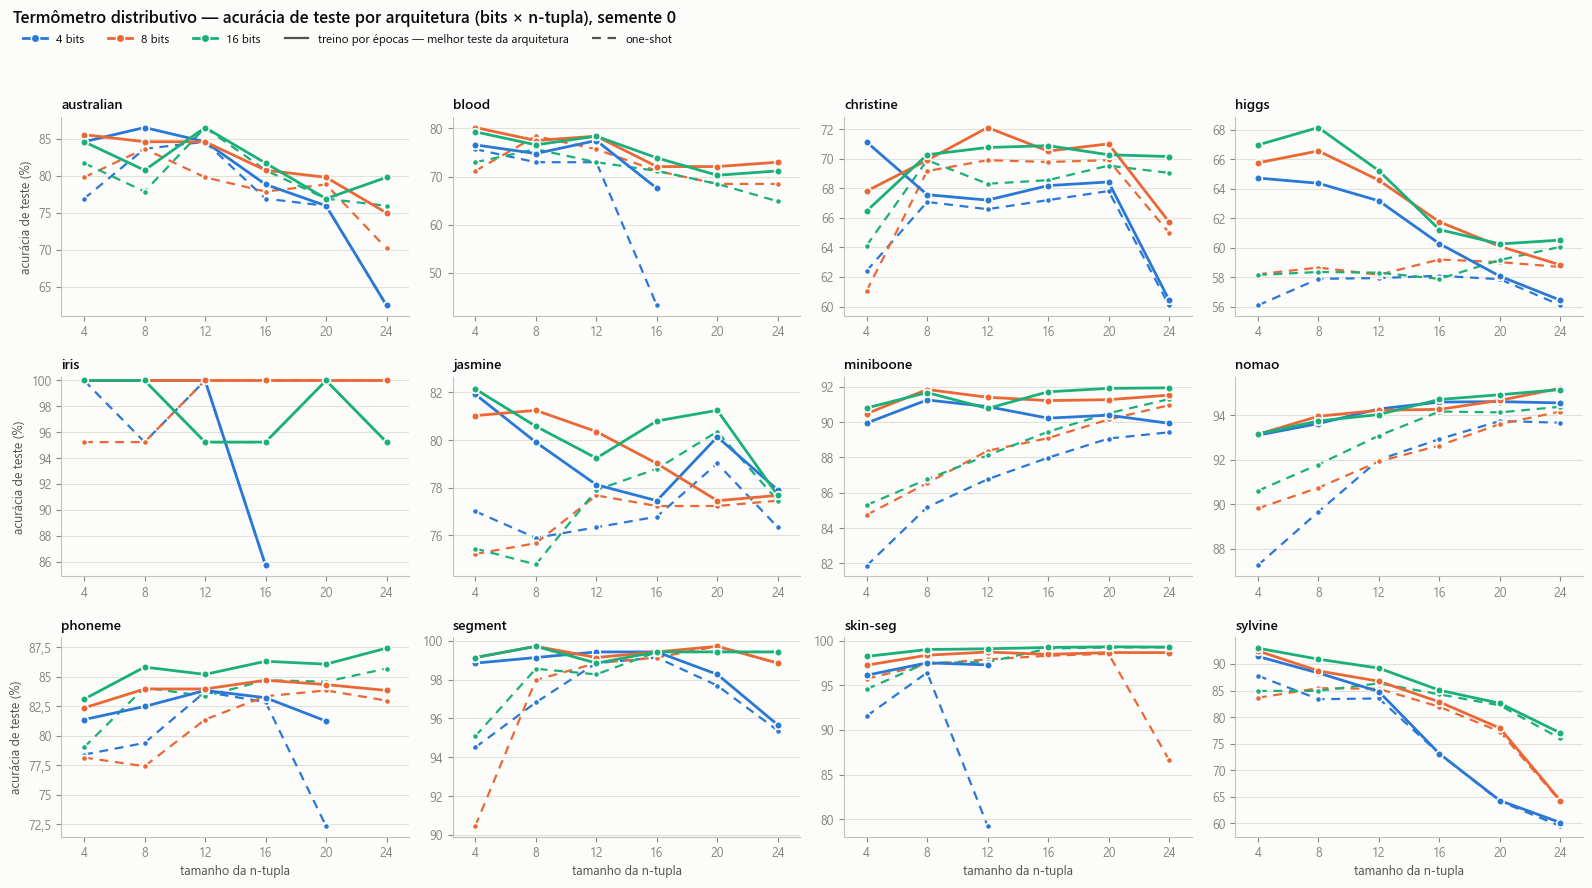

In [8]:
plot_encoding("distributive");

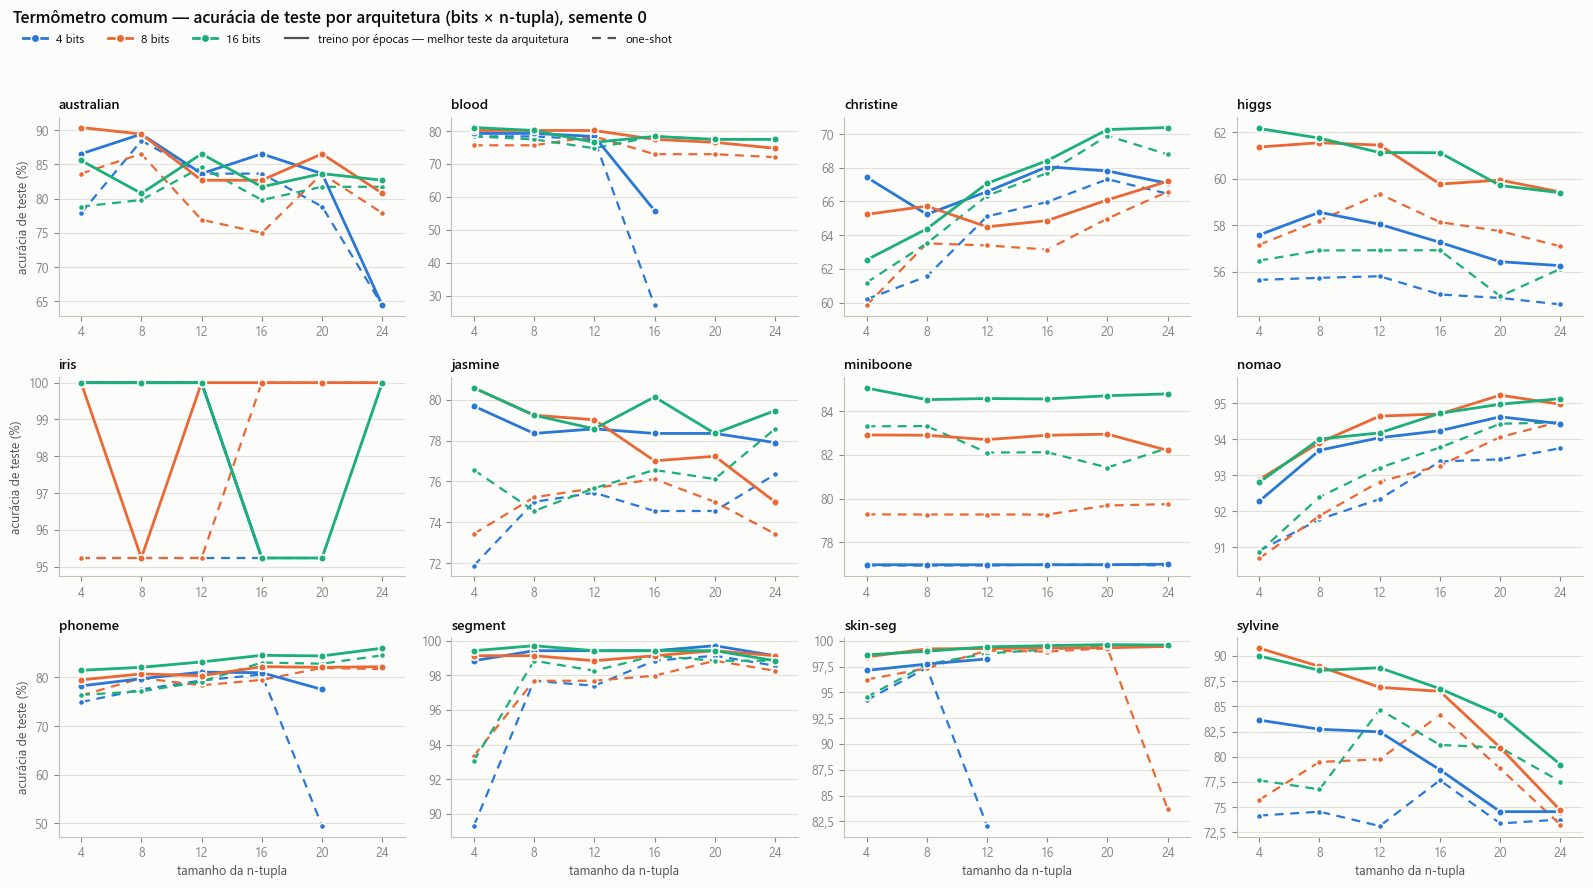

In [9]:
plot_encoding("thermometer");

## Um conjunto, as duas binarizações lado a lado

Troque o nome para ver outro conjunto (os nomes estão na tabela acima).

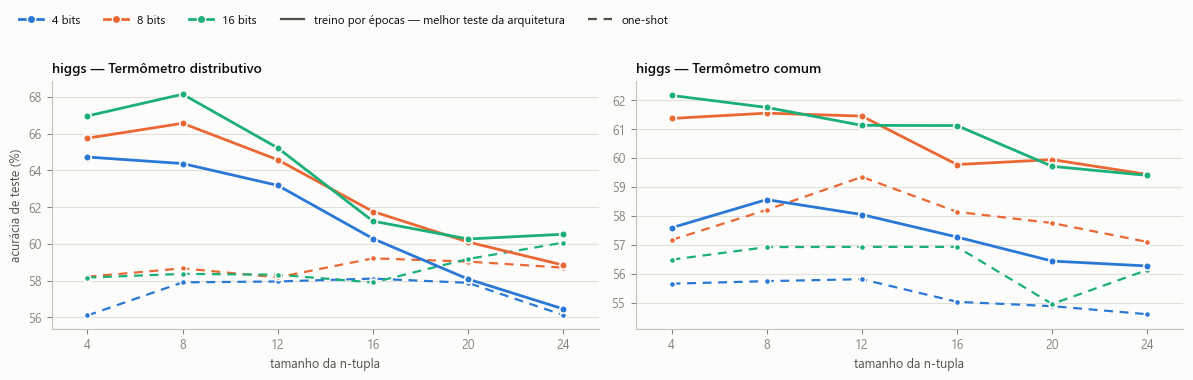

In [10]:
def plot_dataset(dataset):
    encodings = [e for e in ENCODINGS if ((best["dataset"] == dataset) & (best["encoding"] == e)).any()]
    fig, axes = plt.subplots(1, len(encodings), figsize=(6.0 * len(encodings), 3.8), squeeze=False)
    for ax, encoding in zip(axes[0], encodings):
        plot_panel(ax, dataset, encoding, title="%s — %s" % (dataset, ENCODINGS[encoding]))
        ax.set_xlabel("tamanho da n-tupla")
    axes[0, 0].set_ylabel("acurácia de teste (%)")
    fig.legend(handles=legend_handles(), loc="upper left", bbox_to_anchor=(0.01, 1.0), ncol=5, frameon=False, fontsize=8.5)
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    return fig


plot_dataset("higgs");